# 04 — Correlação: operários, privação de sono e fundamentos


## Conceitos

# Covariância e correlação linear

## 1. Relação entre duas variáveis quantitativas

Até aqui, estudamos medidas que descrevem uma variável isoladamente, como média, variância e desvio padrão. Entretanto, muitas análises estatísticas procuram verificar se existe alguma relação entre **duas variáveis quantitativas** observadas nos mesmos indivíduos ou elementos da amostra.

Alguns exemplos são:

- altura e massa corporal de uma pessoa;
- temperatura e salinidade da água do mar;
- velocidade do vento e altura das ondas;
- tempo de estudo e nota obtida em uma prova.

Cada observação é representada por um par ordenado:

$$
(x_i,y_i),
$$

em que $x_i$ é o valor da variável $X$ e $y_i$ é o valor correspondente da variável $Y$ na mesma observação.

Antes de calcular qualquer medida numérica, é recomendável representar os pares de valores em um **diagrama de dispersão**.

## 2. Diagrama de dispersão

No diagrama de dispersão (*scatter plot*), os valores da variável $X$ são colocados no eixo horizontal, enquanto os valores da variável $Y$ são colocados no eixo vertical. Cada par $(x_i,y_i)$ aparece como um ponto no gráfico.

O gráfico permite observar três características importantes da relação entre as variáveis:

1. **Direção**: positiva, negativa ou sem direção evidente;
2. **Forma**: linear ou não linear;
3. **Intensidade**: pontos mais próximos ou mais afastados de uma tendência.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def mostrar_totais(tabela, colunas):
    """Mostra Σ no rodapé sem acrescentar linhas ao DataFrame de cálculo."""
    rodape = {col: (tabela[col].sum() if col in colunas else '') for col in tabela.columns}
    rodape[tabela.columns[0]] = 'Σ'
    display(pd.concat([tabela, pd.DataFrame([rodape])], ignore_index=True))


## 4. Coeficiente de correlação linear de Pearson

O coeficiente de correlação linear de Pearson transforma a covariância em uma medida adimensional e padronizada. Para isso, divide-se a covariância pelo produto dos desvios padrão das duas variáveis:

$$
r=\frac{s_{XY}}{s_Xs_Y}.
$$

Substituindo as expressões da covariância e dos desvios padrão, também podemos escrever:

$$
r=
\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\,
 \sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}.
$$

O coeficiente de correlação sempre se encontra no intervalo:

$$
-1\leq r\leq 1.
$$

Como $s_X$ e $s_Y$ são sempre positivos, o sinal de $r$ é o mesmo sinal da covariância.


## 5. Interpretação do coeficiente de correlação

O sinal do coeficiente indica a **direção** da relação linear:

- $r>0$: correlação linear positiva;
- $r<0$: correlação linear negativa;
- $r\approx 0$: correlação linear ausente ou muito fraca.

O módulo $|r|$ indica o grau de aproximação dos pontos a uma linha reta:

- quanto mais próximo de $1$, mais forte é a associação linear;
- quanto mais próximo de $0$, mais fraca é a associação linear.

Os casos extremos são:

- $r=1$: correlação linear positiva perfeita;
- $r=-1$: correlação linear negativa perfeita;
- $r=0$: ausência de correlação **linear**.

Como orientação inicial, e não como regra universal, pode-se utilizar a seguinte classificação para o módulo de $r$:

| Módulo de $r$ | Interpretação aproximada |
|---:|:---|
| $0{,}00 \leq \lvert r\rvert < 0{,}20$ | muito fraca |
| $0{,}20 \leq \lvert r\rvert < 0{,}40$ | fraca |
| $0{,}40 \leq \lvert r\rvert < 0{,}60$ | moderada |
| $0{,}60 \leq \lvert r\rvert < 0{,}80$ | forte |
| $0{,}80 \leq \lvert r\rvert \leq 1{,}00$ | muito forte |

Esses limites são apenas referências. A interpretação adequada depende da área de estudo, da qualidade das medições, do tamanho da amostra e do fenômeno analisado. Por isso, é recomendável apresentar o valor calculado de $r$ e examinar também o diagrama de dispersão, em vez de informar somente uma classificação verbal.

Por exemplo:

- $r=0{,}87$ indica uma correlação linear positiva muito forte;
- $r=-0{,}72$ indica uma correlação linear negativa forte;
- $r=0{,}08$ indica uma correlação linear positiva muito fraca, praticamente sem tendência linear.


## 6. Cuidados na interpretação

### Correlação não implica causalidade

Uma correlação elevada entre duas variáveis não demonstra, por si só, que uma delas cause alterações na outra.  A associação pode resultar da ação de uma terceira variável, de uma coincidência ou de uma relação indireta entre os fenômenos.

### O coeficiente de Pearson mede relações lineares

É possível obter um valor de $r$ próximo de zero mesmo quando existe uma relação não linear forte entre as variáveis. O diagrama de dispersão é essencial para perceber esse tipo de comportamento.

### Valores extremos podem alterar o resultado

O coeficiente de correlação é sensível a valores discrepantes. Um único ponto muito afastado dos demais pode aumentar, diminuir ou até inverter a correlação observada. Por isso, os valores extremos devem ser investigados, mas não eliminados automaticamente.

### A correlação deve ser analisada no contexto

O valor de $r$ resume apenas a direção e a intensidade da associação linear. Uma análise completa deve considerar o gráfico, a natureza das variáveis, o tamanho da amostra, possíveis erros de medição e o conhecimento sobre o fenômeno estudado.

## Síntese

A sequência lógica da análise é:

1. representar os pares de observações em um diagrama de dispersão;
2. observar a direção, a forma e a intensidade aparente da relação;
3. calcular a covariância para identificar a direção da variação conjunta;
4. calcular o coeficiente de correlação para obter uma medida padronizada da associação linear;
5. interpretar o valor de $r$ em conjunto com o gráfico e com o contexto dos dados.

Assim, a covariância fornece a base matemática da correlação, enquanto o coeficiente de correlação facilita a comparação e a interpretação da relação linear entre duas variáveis.


## Exercício 4 — Operários

4 – Após um tratamento, seis operários submeteram-se a um teste e, mais tarde, mediu-se a produtividade de cada um deles. A partir dos resultados apresentados na tabela abaixo, calcule o coeficiente de correlação entre a nota do teste e a produtividade. O que podemos aferir desse resultado? Calcule também a assimetria da amostra teste e da amostra produtividade e compare-as.

| Operário | 1 | 2  | 3  | 4  | 5  | 6  |
|---------:|--:|---:|---:|---:|---:|---:|
| Teste | 9 | 17 | 20 | 19 | 20 | 23 |
| Produtividade | 22 | 34 | 29 | 33 | 42 | 32 |


,Operário,Teste,Produtividade,Teste·Produtividade
0,1,9,22,198
1,2,17,34,578
2,3,20,29,580
3,4,19,33,627
4,5,20,42,840
5,6,23,32,736
6,Σ,108,192,3559


Teste: média=18.00; assimetria por momento populacional=-1.1528
Produtividade: média=32.00; assimetria por momento populacional=-0.0141
r = 0.6537


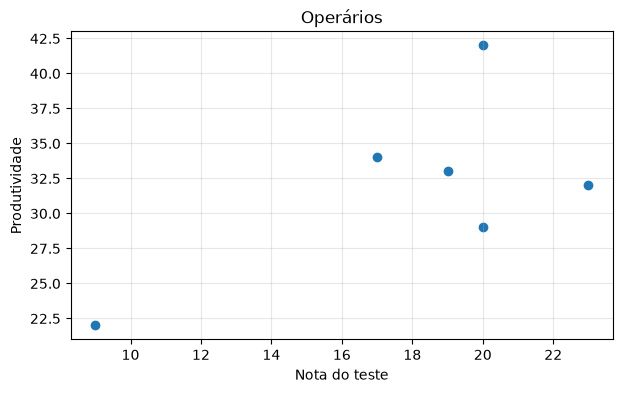

In [2]:
operarios=pd.DataFrame({'Operário':range(1,7),'Teste':[9,17,20,19,20,23],'Produtividade':[22,34,29,33,42,32]})
operarios['Teste·Produtividade']=operarios.Teste*operarios.Produtividade
mostrar_totais(operarios,['Teste','Produtividade','Teste·Produtividade'])
for coluna in ['Teste','Produtividade']:
    s=operarios[coluna]; media=s.mean(); sigma=s.std(ddof=0)
    g=((s-media)**3).mean()/sigma**3
    print(f'{coluna}: média={media:.2f}; assimetria por momento populacional={g:.4f}')
print(f'r = {operarios.Teste.corr(operarios.Produtividade):.4f}')
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(operarios.Teste,operarios.Produtividade)
ax.set(xlabel='Nota do teste',ylabel='Produtividade',title='Operários'); ax.grid(True,alpha=.3); plt.show()


**Interpretação:** a assimetria resume a forma de cada distribuição; Pearson resume a associação linear entre as duas variáveis nos seis pares observados.


## Exercício 5 — Horas sem dormir

5– Procurando quantificar os efeitos da escassez de sono sobre a capacidade de resolução de problemas simples, um agente tomou ao acaso 10 sujeitos e os submeteu a experimentação. Deixou-os sem dormir por diferentes números de horas, após o que solicitou que os mesmos resolvessem os itens "contas de adicionar" de um teste. Obteve, assim, os seguintes dados: 

| Nº de erros — Y | Horas sem dormir — X |
|----------------:|----------------------:|
| 8  | 8  |
| 6  | 8  |
| 6  | 12 |
| 10 | 12 |
| 8  | 16 |
| 14 | 16 |
| 14 | 20 |
| 12 | 20 |
| 16 | 24 |
| 12 | 24 |

Calcule o coeficiente de correlação. Pode-se concluir que horas sem dormir afeta a capacidade de um sujeito durante um teste?


,Horas sem dormir,Erros,X·Y,X²,Y²
0,8,8,64,64,64
1,8,6,48,64,36
2,12,6,72,144,36
3,12,10,120,144,100
4,16,8,128,256,64
5,16,14,224,256,196
6,20,14,280,400,196
7,20,12,240,400,144
8,24,16,384,576,256
9,24,12,288,576,144


r = 0.8015


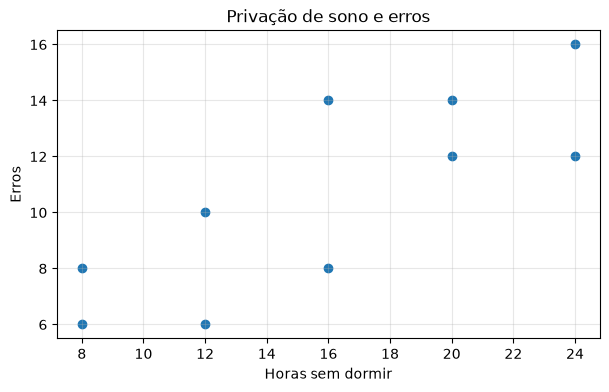

In [3]:
sono=pd.DataFrame({'Horas sem dormir':[8,8,12,12,16,16,20,20,24,24],'Erros':[8,6,6,10,8,14,14,12,16,12]})
sono['X·Y']=sono['Horas sem dormir']*sono.Erros
sono['X²']=sono['Horas sem dormir']**2
sono['Y²']=sono.Erros**2
mostrar_totais(sono,['Horas sem dormir','Erros','X·Y','X²','Y²'])
print(f'r = {sono["Horas sem dormir"].corr(sono.Erros):.4f}')
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(sono['Horas sem dormir'],sono.Erros)
ax.set(xlabel='Horas sem dormir',ylabel='Erros',title='Privação de sono e erros'); ax.grid(True,alpha=.3); plt.show()


**Interpretação:** a direção e a intensidade da associação observada não bastam para afirmar um efeito causal. O enunciado descreve uma experimentação, mas faltam informações sobre controle de fatores, ordem e condições das medições.
